In [1]:
from datetime import datetime
import requests
import pandas as pd
import numpy as np
import time
# --- HÀM TẢI DỮ LIỆU TỪ BINANCE ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.us/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        response = requests.get(general_url, params=params)
        if response.status_code != 200:
            print("Error:", response.status_code, response.text)
            break

        data = response.json()
        if not data:
            break
        all_klines.extend(data)

        last_ts = data[-1][0]
        start_time = last_ts + 1
        time.sleep(0.3)

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "open", "high", "low", "close", "volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "open", "close", "high", "low", "volume"]]
    df.columns = ["timestamp", "open", "close", "high", "low", "volume"]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df[["open", "close", "high", "low", "volume"]] = df[["open", "close", "high", "low", "volume"]].astype(float)
    df["date"] = df["timestamp"].dt.date
    return df


In [27]:
# --- NHẬP THỜI GIAN ---
symbols = ["BTCUSDT",'XRPUSDT','ETHUSDT','PAXGUSDT']
interval = "15m"
start_date = "01/05/2020"
end_date = "30/06/2025"
df = pd.DataFrame()
for symbol in symbols:
  data = fetch_binance_kline_df(symbol, interval, start_date, end_date)
  if symbol == 'BTCUSDT':
    df[f'{symbol}_close'] = data['close']
  else:
    data['vwap'] = (data['high'] + data['close'] + data['low'])/3 * data['volume']
    # df['mavwap'] = data['vwap'].rolling(window = 20).mean()/ data['volume'].rolling(window = 20).sum()
    df[f'{symbol}_close'] = data['vwap'].rolling(window = 20).mean()/ data['volume'].rolling(window = 20).sum()
df

,BTCUSDT_close,XRPUSDT_close,ETHUSDT_close,PAXGUSDT_close
0,8690.00,NaN,NaN,NaN
1,8698.26,NaN,NaN,NaN
2,8734.08,NaN,NaN,NaN
3,8697.23,NaN,NaN,NaN
4,8727.21,NaN,NaN,NaN
...,...,...,...,...
181008,107056.17,NaN,125.162226,NaN
181009,107241.32,NaN,125.152404,NaN
181010,107064.34,NaN,125.140348,NaN
181011,107144.71,NaN,124.785275,NaN


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

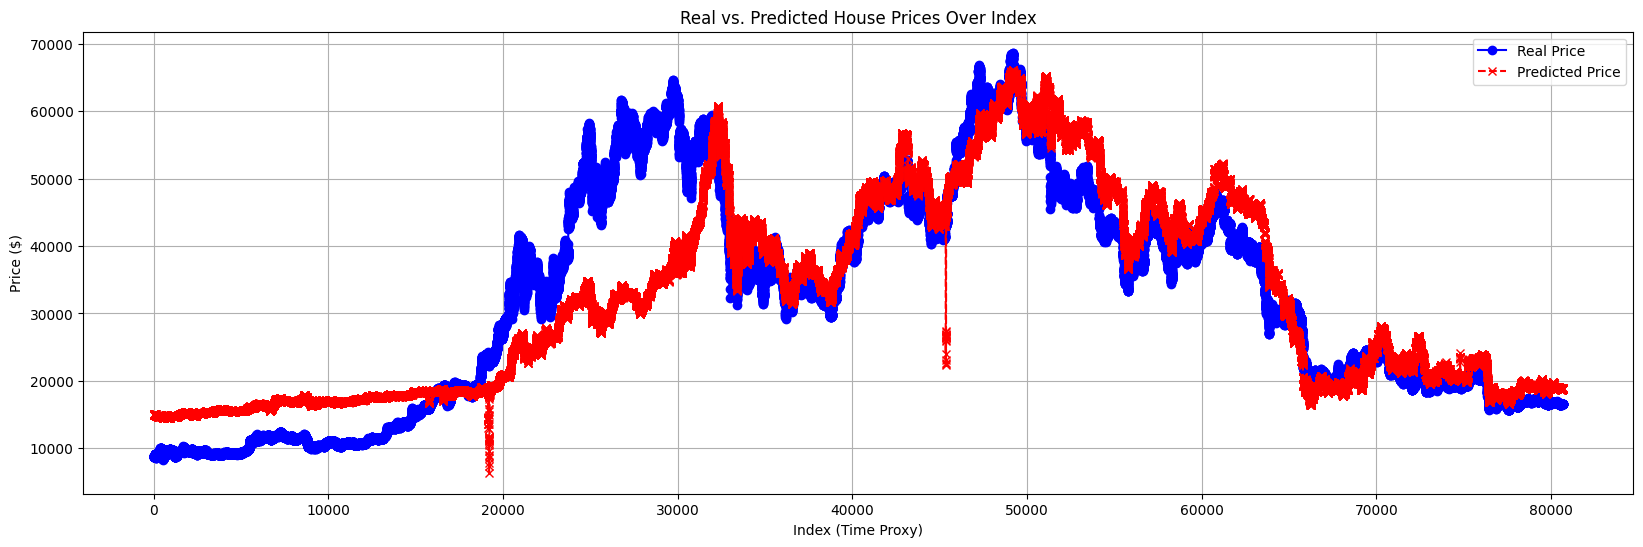

In [28]:
df['BTCUSDT_close_after'] = df['BTCUSDT_close'].shift(-1)
df = df.dropna()
X= df[['XRPUSDT_close', 'ETHUSDT_close', 'PAXGUSDT_close']]
y= df['BTCUSDT_close_after']


# Step 3: Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Train model and predict
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Step 5: Create a DataFrame for test data with index
# Since test set is small (1 row), let's predict on the entire dataset for more points
y_pred_all = model.predict(X)
results = pd.DataFrame({
    'Real Price': y,
    'Predicted Price': y_pred_all,
    'Index': range(len(y))  # Proxy for time
})

# Step 6: Plot real vs. predicted prices over index
plt.figure(figsize=(20, 6))
plt.plot(results['Index'], results['Real Price'], marker='o', color='blue', label='Real Price', linestyle='-')
plt.plot(results['Index'], results['Predicted Price'], marker='x', color='red', label='Predicted Price', linestyle='--')
plt.xlabel('Index (Time Proxy)')
plt.ylabel('Price ($)')
plt.title('Real vs. Predicted House Prices Over Index')
plt.legend()
plt.grid(True)
plt.show()

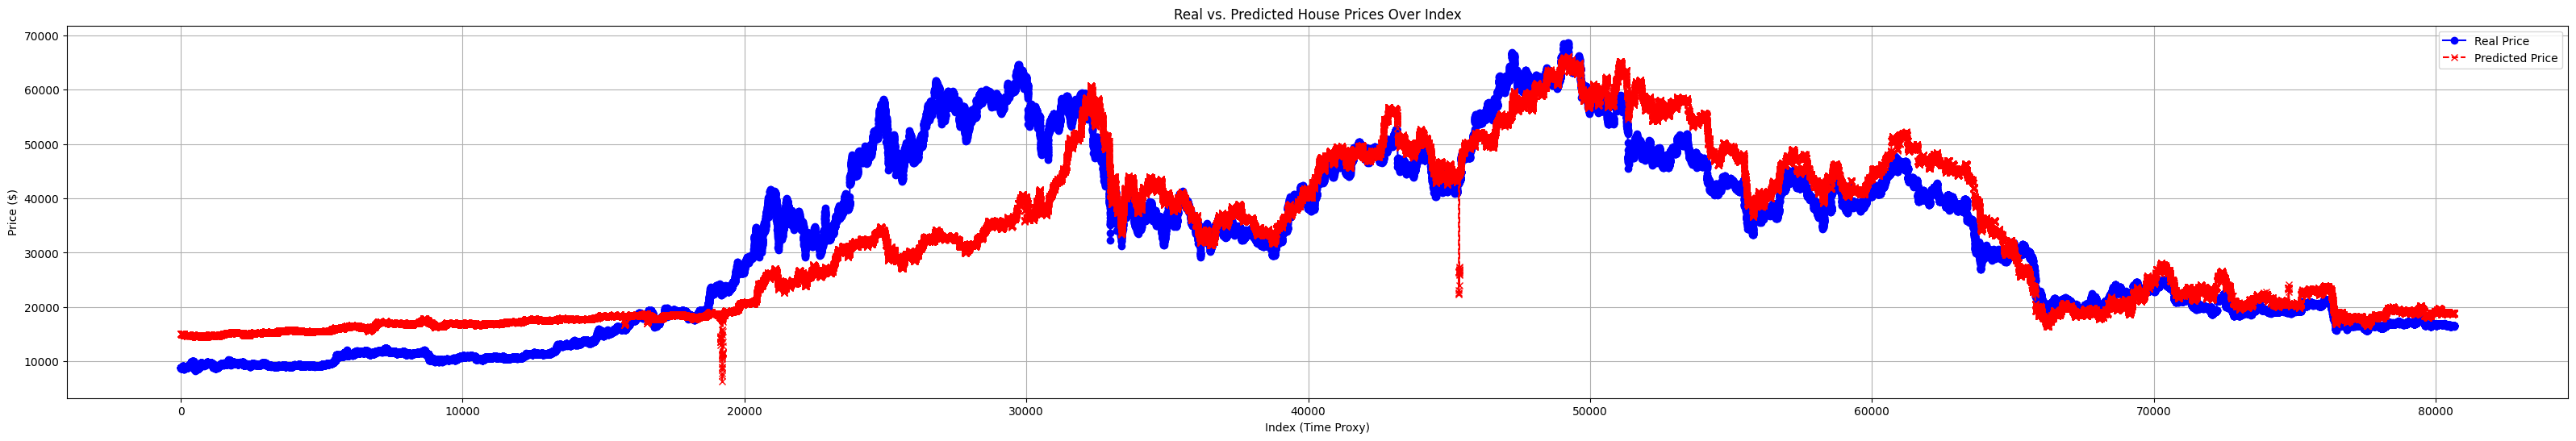

In [29]:
# Step 6: Plot real vs. predicted prices over index
plt.figure(figsize=(40, 6))
plt.plot(results['Index'], results['Real Price'], marker='o', color='blue', label='Real Price', linestyle='-')
plt.plot(results['Index'], results['Predicted Price'], marker='x', color='red', label='Predicted Price', linestyle='--')
plt.xlabel('Index (Time Proxy)')
plt.ylabel('Price ($)')
plt.title('Real vs. Predicted House Prices Over Index')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse}")

# Calculate Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae}")

Mean Squared Error (MSE): 249455299.18819487
Mean Absolute Error (MAE): 13674.427023103934
